# Selecting Features

The goal of this notebook is to do feature exploration a head of writing the preprocessing.py file

## Summary

**Goal.** Make a decision for each of the 321 features, check those decisions on the data, and build a first preprocessing pipeline for `src/preprocessing.py`.

**Inputs.** `x_train` / `x_test` loaded with `helpers.load_csv_data`; the decisions in `src/feature_spec.py`; `reg_logistic_regression` from `implementations.py` for the CV checks.

### What we decided

| | Features | Rule |
|---|---|---|
| **Kept** | 77 (35 binary, 6 ordinal, 14 continuous, 22 nominal) | Default: keep unless a drop rule applies |
| **Dropped on purpose** | 149 | Not about health (metadata, phone screening, weights, child questions), or redundant with a kept feature |
| **Optional modules** | 89 | ≥ 90 % NaN |
| **Leaky** | 6 | Asked only because of a heart condition (`HAREHAB1`, aspirin follow-ups); left out by default, tested as E9 |

### What the checks showed

- **Redundancy and skip patterns hold in the data**, so the "redundant" drops and the skip-pattern fills (`POORHLTH`, `BPMEDS`) are justified.
- **Dropping lost no signal.** Every strong dropped feature (univariate AUC > 0.6) is a recoding of a kept one, mostly age. Module features are weak (AUC ≤ 0.56).
- **Clipping continuous features** to the 0.5–99.5 % training quantiles removes absurd tails (`PA1MIN_` 54,000 → 4,340 min/week, `_DRNKWEK` 532 → 42 drinks/week) and changes at most about 1 % of any feature.
- **The pipeline** turns the 77 features into **263 columns** (bias, 55 numeric, 39 missing indicators, 168 one-hot levels) in about 2 s, with no NaN. Test columns come out with mean ≈ 0 and std ≈ 1 using training statistics.

### Cross-validation results

Protocol: 5-fold stratified CV (seed 42), `reg_logistic_regression` (λ = 1e-4, γ = 1, 200 iterations), threshold tuned on the out-of-fold predictions, F1 on the positive class.

| Configuration | F1 | Δ vs baseline | Folds better | Decision |
|---|---|---|---|---|
| **Baseline** (263 columns) | **0.4271 ± 0.0025** | | | |
| Stricter NaN threshold (0.7 / 0.5 / 0.3) | 0.4253–0.4259 | −0.0012 to −0.0018 | 0–1 / 5 | Keep 0.9 |
| No missing indicators | 0.4276 | +0.0005 | 4 / 5 | Drop indicators (same score, 39 fewer columns) |
| Ordinals one-hot encoded | 0.4271 | +0.0000 | 3 / 5 | Keep ordinals numeric |
| With leaky features (E9) | 0.4371 | +0.0100 | 5 / 5 | Leave out during development; decide at the freeze |

The best threshold is about **0.20**, not 0.5: only 9 % of the labels are positive.

## Setup

In [1]:
import itertools
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from helpers import load_csv_data
import time


# just for formatting

np.set_printoptions(suppress=True, linewidth=120)

BLUE, ORANGE, GREEN, GOLD = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "font.size": 9,
    "axes.titlesize": 10, "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": MUTED, "axes.edgecolor": "#b5b4ae", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

In [2]:
data_dir = f"{ROOT}/data"

In [3]:
start = time.time()
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_dir)
end = time.time()
print(f"Loaded in {end-start} seconds")
print("x_train:", x_train.shape, "| x_test:", x_test.shape, "| y_train:", y_train.shape)

Loaded in 29.870004892349243 seconds
x_train: (328135, 321) | x_test: (109379, 321) | y_train: (328135,)


In [4]:
with open(f"{data_dir}/x_train.csv") as f:
    feature_names = f.readline().strip().split(",")[1:]  # skip the Id column
assert len(feature_names) == x_train.shape[1]

y01 = (y_train == 1).astype(float)  # {0, 1} labels for logistic regression
idx = {name: j for j, name in enumerate(feature_names)}


def col(name, X=None):
    return (x_train if X is None else X)[:, idx[name]]


nan_raw = np.isnan(x_train).mean(axis=0)  # NaN share per feature, before any cleaning
print(f"positives: {y01.mean():.1%}")

positives: 8.8%


### Where the feature spec comes from

`src/feature_spec.py` is written by hand, not generated by code. It records a decision for each of the 321 features, based on two sources:

1. **The BRFSS 2015 codebook**, for what each code means: `7`/`9` (and `77`/`99`) are "don't know" / "refused", `88` means "none" in day counts, and the skip patterns say which questions are asked only after a certain answer.
2. **Value counts on `x_train.csv`**, to confirm those codes actually appear in this release. This check also found that `_DRNKWEK` is still ×100, that some calculated variables hide missing codes (e.g. `99900`), and that some columns are duplicates.

Each feature ends up in exactly one place:

- **`SPEC`** (77 features): kept, each with its type (binary / ordinal / continuous / nominal), missing codes and value remaps.
- **`DROP`** (149 features): removed on purpose, each with a stated reason.
- **`LEAKY`** (6 features): follow-up questions asked only because of a heart condition, e.g. `HAREHAB1` (cardiac rehab). Left out by default; tested separately in the leakage experiment (E9).
- **Everything else** (89 features): optional-module questions with ≥ 90 % missing values, dropped by `MODULE_NAN_THRESHOLD`.

**Drop rules.** Features are kept by default. A feature is dropped for one of these reasons, checked in order:

| Rule | Examples |
|---|---|
| Not about the respondent's health: interview metadata, phone screening, survey weights, questions about a child in the household | `IDATE`, `SEQNO`, `CTELENUM`, `_LLCPWT`, `_CRACE1` |
| Redundant: another kept column has the same information | `_RFHLTH` (from `GENHLTH`), `_AGEG5YR` (from `_AGE80`), raw diet and activity answers (summarised by `_FRUTSUM`, `_VEGESUM`, `PA1MIN_`) |
| Not usable as a feature: dates or places of events, or values computed only from age and sex | `FLSHTMY2`, `WHRTST10`, `MAXVO2_`, `FC60_` |
| Optional module with ≥ 90 % missing values | diabetes, cancer screening and caregiving modules |

When two columns carry the same information, we keep the more detailed one: continuous over binned (`_AGE80` over `_AGEG5YR`), more categories over a yes/no flag (`BPHIGH4` over `_RFHYPE5`), and cleaned over raw codes (`HTM4` over `HEIGHT3`).

**How it is checked.** The next sections test the spec instead of trusting it:

- Every feature is covered exactly once.
- The redundancy and skip-pattern claims are checked in the data.
- The strongest dropped features (by univariate AUC) all have a kept equivalent, so dropping them loses no unique signal.
- No hidden missing codes remain after cleaning.
- Cross-validation tests the decisions that could go either way: the missing-value threshold, missing indicators and ordinal encoding.

In [5]:
from src import feature_spec as fs
from implementations import reg_logistic_regression

## Decisions On Every Single Feature

`src/feature_spec.py` puts each of the 321 features in exactly one bucket:

| Bucket | Meaning |
|---|---|
| `SPEC` | **kept**, with its kind (binary, ordinal, continuous, nominal), its missing codes and its remaps |
| `DROP` | **dropped on purpose**, with a one-line reason |
| `LEAKY` | follow-up questions asked *because of* a heart condition: dropped by default, tested in section 9 |
| module | optional-module questions with ≥ 90 % NaN, dropped by the rule `MODULE_NAN_THRESHOLD` |

The cell checks that no feature is forgotten or listed twice, and that the module rule really only removes nearly empty columns.

In [6]:
kept, dropped, leaky = set(fs.SPEC), set(fs.DROP), set(fs.LEAKY)
assert (kept | dropped | leaky) <= set(feature_names), "spec names a feature that doesn't exist"
assert not (kept & dropped or kept & leaky or dropped & leaky), "a feature is in two buckets"
module = [n for n in feature_names if n not in kept | dropped | leaky]
assert all(nan_raw[idx[n]] >= fs.MODULE_NAN_THRESHOLD for n in module), "a 'module' feature has < 90 % NaN"
assert all(nan_raw[idx[n]] < fs.MODULE_NAN_THRESHOLD for n in kept), "a kept feature is >= 90 % NaN"

bucket = {n: "kept" if n in kept else "dropped" if n in dropped else "leaky" if n in leaky else "module"
          for n in feature_names}
for b in ["kept", "dropped", "leaky", "module"]:
    print(f"{b:>8}: {sum(v == b for v in bucket.values()):>3}")

kinds = [fs.SPEC[n][0] for n in fs.SPEC]
print("\nkept features by kind:", {k: kinds.count(k) for k in ["binary", "ordinal", "continuous", "nominal"]})

reasons = {}
for n, r in fs.DROP.items():
    reasons.setdefault(r.split(" (")[0] if r.startswith("redundant") else r, []).append(n)
print("\ndropped features by reason:")
for r, names in sorted(reasons.items(), key=lambda t: -len(t[1])):
    print(f"  {len(names):>3}  {r}: {' '.join(names[:8])}{' …' if len(names) > 8 else ''}")

    kept:  77
 dropped: 149
   leaky:   6
  module:  89

kept features by kind: {'binary': 35, 'ordinal': 6, 'continuous': 14, 'nominal': 22}

dropped features by reason:
   31  redundant with _PACAT1 / PA1MIN_ / STRFREQ_: EXRACT11 EXEROFT1 EXERHMM1 EXRACT21 EXEROFT2 EXERHMM2 STRENGTH METVL11_ …
   22  redundant with _FRUTSUM / _VEGESUM: FRUITJU1 FRUIT1 FVBEANS FVGREEN FVORANG VEGETAB1 FTJUDA1_ FRUTDA1_ …
   21  phone screening / household listing: CTELENUM PVTRESD1 COLGHOUS STATERES CELLFON3 LADULT NUMADULT NUMMEN …
   10  interview metadata, not health information: FMONTH IDATE IMONTH IDAY IYEAR DISPCODE SEQNO _PSU …
    7  survey design or weighting variable: _STSTR _STRWT _RAWRAKE _WT2RAKE _CLLCPWT _DUALCOR _LLCPWT
    6  about a random child in the household, not the respondent: _CHISPNC _CRACE1 _CPRACE RCSGENDR RCSRLTN2 CASTHDX2
    6  redundant with _RACE: _PRACE1 _MRACE1 _HISPANC _RACEG21 _RACEGR3 _RACE_G1
    4  redundant with _ASTHMS1: ASTHMA3 ASTHNOW _LTASTH1 _CASTHM1
    4 

**Takeaway.**
- **77 features are kept** (35 binary, 6 ordinal, 14 continuous, 22 nominal), out of 321.
- **149 are dropped on purpose.** About 40 are not about health at all (interview metadata, phone screening, survey weights, questions about a child). Most of the rest are **redundant copies**: BRFSS ships each concept several times, as the raw answer plus one or more calculated versions (age ×4, race ×7, the physical-activity block ×30, the fruit/vegetable block ×22).
- **89 optional-module questions** with ≥ 90 % NaN are dropped by rule, and 6 leaky follow-ups are set aside.
- Rule used to pick the representative of a group: prefer the **calculated** variable when it is already decoded (`_AGE80`, `_BMI5`, `_SMOKER3`, `_DRNKWEK`, `_FRUTSUM`), and the **raw** answer when the calculated one throws information away (`BPHIGH4` keeps "borderline", which `_RFHYPE5` merges into "no").

## Checking Redundancy and Skip Pattern Claims

In [7]:
def crosstab(a, b):
    # Counts of each (a, b) pair, NaN shown as -1.
    a, b = np.nan_to_num(a, nan=-1), np.nan_to_num(b, nan=-1)
    pairs, counts = np.unique(np.column_stack([a, b]), axis=0, return_counts=True)
    return {(int(p[0]), int(p[1])): int(c) for p, c in zip(pairs, counts)}


both = ~np.isnan(col("_DRDXAR1")) & ~np.isnan(col("HAVARTH3"))
print("1) _DRDXAR1 == HAVARTH3 on every row where both are present:",
      bool(np.all(col("_DRDXAR1")[both] == col("HAVARTH3")[both])))

print("\n2) _SMOKER3 (1 daily, 2 some days, 3 former, 4 never, 9 unknown) vs SMOKDAY2:")
print("  ", crosstab(col("_SMOKER3"), col("SMOKDAY2")))

age, sex, vo2 = col("_AGE80"), col("SEX"), col("MAXVO2_")
ok = vo2 < 999
A = np.column_stack([np.ones(ok.sum()), age[ok], sex[ok], age[ok] * sex[ok]])
w = np.linalg.solve(A.T @ A, A.T @ vo2[ok])
r2 = 1 - np.var(vo2[ok] - A @ w) / np.var(vo2[ok])
print(f"\n3) MAXVO2_ explained by age and sex alone: R^2 = {r2:.3f}")

g5 = col("_AGEG5YR")
print(f"\n4) correlation _AGE80 vs _AGEG5YR (excluding 14 = unknown): "
      f"{np.corrcoef(age[g5 < 14], g5[g5 < 14])[0, 1]:.3f}")

phys, ment, poor = col("PHYSHLTH"), col("MENTHLTH"), col("POORHLTH")
both_none = (phys == 88) & (ment == 88)
print(f"\n5) POORHLTH is NaN for {np.isnan(poor).sum():,} rows; "
      f"PHYSHLTH = MENTHLTH = 88 (none) for {(np.isnan(poor) & both_none).sum():,} of them, "
      f"and POORHLTH is present for {(~np.isnan(poor) & both_none).sum()} rows with both = 88")

bp, bpmeds = col("BPHIGH4"), col("BPMEDS")
print("\n6) BPMEDS present, by BPHIGH4 answer:",
      {int(v): int((~np.isnan(bpmeds) & (bp == v)).sum()) for v in [1, 2, 3, 4, 7, 9]})

1) _DRDXAR1 == HAVARTH3 on every row where both are present: True

2) _SMOKER3 (1 daily, 2 some days, 3 former, 4 never, 9 unknown) vs SMOKDAY2:
   {(1, 1): 32444, (2, 2): 13230, (3, 3): 90838, (4, -1): 178357, (9, -1): 13022, (9, 7): 68, (9, 9): 176}

3) MAXVO2_ explained by age and sex alone: R^2 = 0.992

4) correlation _AGE80 vs _AGEG5YR (excluding 14 = unknown): 0.996

5) POORHLTH is NaN for 159,860 rows; PHYSHLTH = MENTHLTH = 88 (none) for 159,860 of them, and POORHLTH is present for 0 rows with both = 88

6) BPMEDS present, by BPHIGH4 answer: {1: 131801, 2: 0, 3: 0, 4: 0, 7: 0, 9: 0}


**Takeaway.**
1. `_DRDXAR1` is an exact copy of `HAVARTH3`.
2. `_SMOKER3` is a lossless recode of `SMOKE100` + `SMOKDAY2`: each of its values maps to exactly one answer pair, so the raw pair can go.
3. `MAXVO2_` and `FC60_` look like fitness measures, but are **formulas of age and sex** (R² = 0.99). They add nothing beyond `_AGE80` and `SEX`.
4. The age encodings are interchangeable (r = 0.996); `_AGE80` keeps the most detail.
5. `POORHLTH` is NaN **exactly** when both day counts are "none". Not asked therefore means 0 days, so the spec fills 0 instead of imputing: this recovers half the column.
6. `BPMEDS` is asked only to people with high blood pressure. For everyone else the spec fills "no" (2); the remaining NaN are real non-answers.

## Did dropping lose any signal?

A quick, model-free ranking: the **univariate AUC** of each feature, i.e. how well that feature alone separates positives from negatives (0.5 = useless, 1 = perfect).
- For features with ≤ 100 distinct values, each value is scored by its positive rate (NaN counts as its own value). This handles nominal codes without assuming an order.
- For the others, the raw value is the score, flipped if needed, so AUC ≥ 0.5.

Kept features are scored after cleaning (section 5); dropped ones on their raw values.

In [8]:
def auc(score, y):
    # Area under the ROC curve with ties counted as 1/2 (Mann-Whitney U / (P * N)).
    values, inv = np.unique(score, return_inverse=True)
    pos = np.bincount(inv, weights=y, minlength=len(values))
    neg = np.bincount(inv, minlength=len(values)) - pos
    return (np.sum(pos * (np.cumsum(neg) - neg)) + 0.5 * np.sum(pos * neg)) / (pos.sum() * neg.sum())


def univariate_auc(c, y, max_levels=100):
    c = np.where(np.isnan(c), -1e12, c)  # NaN = its own value
    values, inv = np.unique(c, return_inverse=True)
    if len(values) <= max_levels:
        rate = np.bincount(inv, weights=y) / np.bincount(inv)
        return auc(rate[inv], y)
    a = auc(c, y)
    return max(a, 1 - a)

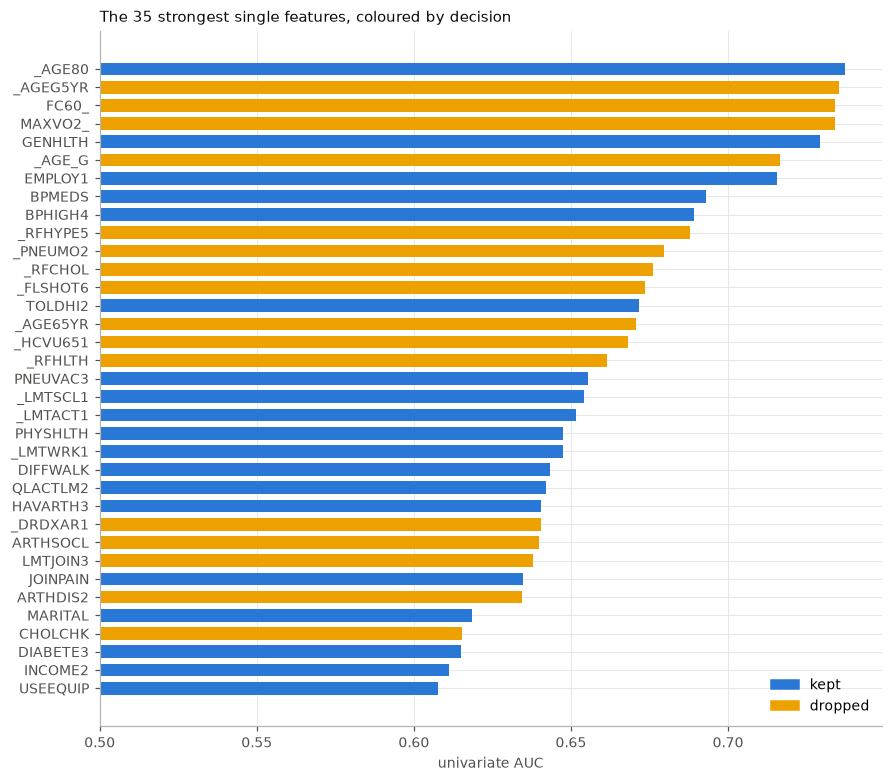

strongest dropped features and why:
   0.735  _AGEG5YR   redundant with _AGE80
   0.734  FC60_      computed from age and sex only (999 = missing)
   0.734  MAXVO2_    computed from age and sex only (999 = missing)
   0.717  _AGE_G     redundant with _AGE80
   0.688  _RFHYPE5   redundant with BPHIGH4
   0.679  _PNEUMO2   redundant with PNEUVAC3 (age 65+ only)
   0.676  _RFCHOL    redundant with TOLDHI2
   0.674  _FLSHOT6   redundant with FLUSHOT6 (age 65+ only)
   0.671  _AGE65YR   redundant with _AGE80
   0.668  _HCVU651   redundant with HLTHPLN1 (coverage, ages 18-64 only)
   0.661  _RFHLTH    redundant with GENHLTH
   0.640  _DRDXAR1   redundant with HAVARTH3 (identical values)

strongest module features: BLDSUGAR 0.555, DOCTDIAB 0.554, INSULIN 0.554, CHKHEMO3 0.554, DIABEYE 0.554, FEETCHK2 0.554, EYEEXAM 0.554, DIABEDU 0.554, FEETCHK 0.554, SCNTLWK1 0.533, DRADVISE 0.529, SCNTWRK1 0.526, SCNTPAID 0.52
leaky features: CVDASPRN 0.517, HAREHAB1 0.513, ASPUNSAF 0.510, RDUCHART 0.510, R

In [9]:
def clean_columns(x, feature_names, features):
    # Cleaned copies of the requested features, as a dict name -> 1-D array.
    index = {n: j for j, n in enumerate(feature_names)}
    cache = {}

    def get(name):
        if name not in cache:
            kind, codes, remap = fs.SPEC.get(name, ("nominal", [], {}))  # leaky features: raw
            c = x[:, index[name]].astype(np.float64)  # astype copies
            c[np.isin(c, codes)] = np.nan
            for old, new in remap.items():
                c[c == old] = new
            cache[name] = c * fs.SCALE.get(name, 1.0)
        return cache[name]

    cols = {n: get(n) for n in features}
    for name, value, condition in fs.FILLS:
        if name in cols:
            c = cols[name]
            c[np.isnan(c) & condition(get)] = value
    return cols


clean = clean_columns(x_train, feature_names, list(fs.SPEC))
uauc = {n: univariate_auc(clean[n] if n in clean else col(n), y01) for n in feature_names}
ranked = sorted(feature_names, key=lambda n: -uauc[n])

top = ranked[:35]
colors = {"kept": BLUE, "dropped": GOLD, "leaky": ORANGE, "module": MUTED}
fig, ax = plt.subplots(figsize=(8, 7), constrained_layout=True)
ax.barh(range(len(top)), [uauc[n] - 0.5 for n in top], left=0.5,
        color=[colors[bucket[n]] for n in top], height=0.7)
ax.set_yticks(range(len(top)), top)
ax.invert_yaxis()
ax.set_xlim(0.5, None)
ax.set_xlabel("univariate AUC")
ax.set_title("The 35 strongest single features, coloured by decision")
handles = [plt.Rectangle((0, 0), 1, 1, color=colors[b]) for b in ["kept", "dropped"]]
ax.legend(handles, ["kept", "dropped"], loc="lower right")
plt.show()

print("strongest dropped features and why:")
for n in [n for n in ranked if bucket[n] == "dropped"][:12]:
    print(f"   {uauc[n]:.3f}  {n:<10} {fs.DROP[n]}")
print("\nstrongest module features:", ", ".join(f"{n} {uauc[n]:.3f}" for n in ranked if bucket[n] == "module")[:200])
print("leaky features:", ", ".join(f"{n} {uauc[n]:.3f}" for n in ranked if bucket[n] == "leaky"))

**Takeaway.**
- The strongest single features are **age** (AUC 0.74), **general health**, **employment** (mostly through "retired", i.e. age again), **blood pressure**, **cholesterol**, **vaccines** (which track age), **activity limits** and **arthritis**. All of them are kept.
- **Every strong dropped feature is a copy of a kept one**: age encodings (`_AGEG5YR`, `_AGE_G`, `_AGE65YR`, and `MAXVO2_`/`FC60_`, which are age formulas), `_RFHYPE5` (= `BPHIGH4`), `_RFCHOL` (= `TOLDHI2`), the age-65+ vaccine recodes, and the raw arthritis follow-ups. Nothing with independent signal was lost.
- **Module features are weak** (AUC ≤ 0.56). Their signal is mostly "was asked the diabetes module" = "is diabetic", which `DIABETE3` already carries.
- The **leaky features score low here** because they are 99.8 % NaN. Their effect is concentrated on a few hundred rows, which section 9 measures directly.

## Cleaning Missing Values

- from the columns that we decided to keep, do features contain real answers ?
- **No code value survives:** binary features hold only {1, 2}, and the other kinds are listed with their value ranges.
- **How much missingness was hidden as codes**, i.e. the NaN share before vs after cleaning.

In [10]:
rows = []
for n, (kind, codes, remap) in fs.SPEC.items():
    c = clean[n]
    values = np.unique(c[~np.isnan(c)])
    if kind == "binary":
        assert set(values) <= {1.0, 2.0}, f"{n}: unexpected values {values}"
    rows.append((n, kind, nan_raw[idx[n]], np.isnan(c).mean(), values))

print(f"{'feature':<10} {'kind':<11} {'NaN raw':>8} {'cleaned':>8}   values")
for n, kind, before, after, values in sorted(rows, key=lambda r: -(r[3] - r[2])):
    shown = " ".join(f"{v:g}" for v in values) if len(values) <= 12 else f"{values.min():g} .. {values.max():g} ({len(values)} values)"
    print(f"{n:<10} {kind:<11} {before:>8.1%} {after:>8.1%}   {shown}")

feature    kind         NaN raw  cleaned   values
INCOME2    ordinal         0.8%    17.9%   1 2 3 4 5 6 7 8
_PACAT1    ordinal         0.0%    12.6%   1 2 3 4
_RFSEAT2   binary          0.0%     9.6%   1 2
PNEUVAC3   binary          9.5%    17.7%   1 2
_DRNKWEK   continuous      0.0%     5.8%   0 .. 532 (236 values)
_RFBING5   binary          0.0%     5.7%   1 2
DRNKANY5   binary          0.0%     4.9%   1 2
_SMOKER3   nominal         0.0%     4.0%   1 2 3 4
_LMTWRK1   nominal         0.6%     4.1%   1 2 3
_CHOLCHK   nominal         0.0%     3.4%   1 2 3
HIVTST6    binary          9.8%    13.0%   1 2
_LMTACT1   nominal         0.6%     3.5%   1 2 3
_LMTSCL1   nominal         0.6%     3.5%   1 2 3 4
PHYSHLTH   continuous      0.0%     2.2%   0 .. 30 (31 values)
_RACE      nominal         0.0%     1.7%   1 2 3 4 5 6 7 8
MENTHLTH   continuous      0.0%     1.6%   0 .. 30 (31 values)
CRGVEXPT   binary         80.9%    82.3%   1 2
CHECKUP1   ordinal         0.0%     1.4%   1 2 3 4 5
SXORIE

**Takeaway.**
- **Income hides the most:** `INCOME2` goes from 0.8 % to 18 % NaN once "don't know" (77) and "refused" (99) are removed. That's too much to impute silently, so a missing indicator matters here.
- Other large hidden shares: `PNEUVAC3` (9.5 % → 17.7 %, many "don't know" about the pneumonia shot), `_PACAT1` (0 → 12.6 %) and `_RFSEAT2` (0 → 9.6 %), whose code 9 was "unknown".
- The **skip-pattern fills recover two columns**: `POORHLTH` drops from 48.7 % to 1.1 % NaN and `BPMEDS` from 59.8 % to 0.3 %, because "not asked" became 0 days / "no".
- All binary features are clean {1, 2}. Values like 7 in `EMPLOY1` (retired) and `_RACE`, or 8 in `CAREGIV1` (care recipient died), are real answers and are intentionally kept.
- Continuous features keep long tails (`_DRNKWEK` up to 532 drinks/week, `PA1MIN_` up to 54,000 min/week). Section 7 handles them.

## Is missingness informative?

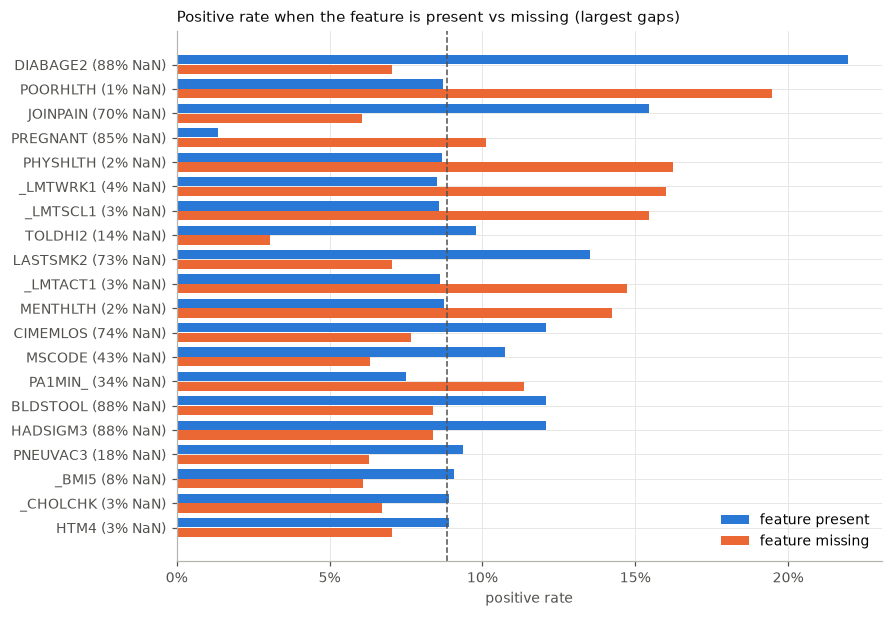

In [11]:
gap = []
for n in fs.SPEC:
    nan = np.isnan(clean[n])
    if 0.01 <= nan.mean() <= 0.99:
        gap.append((n, y01[nan].mean(), y01[~nan].mean(), nan.mean()))
gap.sort(key=lambda t: -abs(t[1] - t[2]))
show = gap[:20]

fig, ax = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
yy = np.arange(len(show))
ax.barh(yy - 0.2, [t[2] for t in show], height=0.38, color=BLUE, label="feature present")
ax.barh(yy + 0.2, [t[1] for t in show], height=0.38, color=ORANGE, label="feature missing")
ax.axvline(y01.mean(), color=MUTED, ls="--", lw=1)
ax.set_yticks(yy, [f"{t[0]} ({t[3]:.0%} NaN)" for t in show])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("positive rate")
ax.set_title("Positive rate when the feature is present vs missing (largest gaps)")
ax.legend(loc="lower right")
plt.show()

**Takeaway.**
- People who **don't answer** a common question (`PHYSHLTH`, `POORHLTH`, the `_LMT*` arthritis limits) are about **twice as likely to be positive** (15–20 % vs 8.8 %). Non-answers are a signal, not noise.
- Missingness is **strongly informative for the conditional questions**:
  - `DIABAGE2` is asked only to diabetics, so "present" means "diabetic".
  - `JOINPAIN` is asked only to people with arthritis.
  - `PREGNANT` is asked only to women aged 18–44, so "missing" means "older or male".
  - `LASTSMK2` is asked only to former smokers.
- For these, a missing indicator lets a linear model use the skip pattern even after imputation. Nominal features don't need one: "missing" is already its own one-hot level.

## Inspecting Continuous Features

Standardization is sensitive to extreme values: a handful of rows with 54,000 minutes of activity per week stretch the scale and squeeze everyone else near 0.
The pipeline therefore **clips each continuous feature to its 0.5–99.5 % training quantiles** before imputing and scaling.

In [12]:
print(f"{'feature':<10} {'min':>8} {'q0.5%':>8} {'median':>8} {'q99.5%':>8} {'max':>9}   rows clipped")
for n, (kind, _, _) in fs.SPEC.items():
    if kind != "continuous":
        continue
    c = clean[n][~np.isnan(clean[n])]
    lo, med, hi = np.quantile(c, [0.005, 0.5, 0.995])
    print(f"{n:<10} {c.min():>8.2f} {lo:>8.2f} {med:>8.2f} {hi:>8.2f} {c.max():>9.2f}   {np.mean((c < lo) | (c > hi)):.2%}")

feature         min    q0.5%   median   q99.5%       max   rows clipped
PHYSHLTH       0.00     0.00     0.00    30.00     30.00   0.00%
MENTHLTH       0.00     0.00     0.00    30.00     30.00   0.00%
POORHLTH       0.00     0.00     0.00    30.00     30.00   0.00%
DIABAGE2       1.00     7.00    52.00    84.00     96.00   0.95%
_AGE80        18.00    18.00    58.00    80.00     80.00   0.00%
CHILDREN       0.00     0.00     0.00     5.00     77.00   0.26%
_BMI5         12.02    17.16    26.93    55.61     97.65   1.00%
HTM4           0.91     1.47     1.68     1.96      2.41   0.82%
_DRNKWEK       0.00     0.00     0.23    42.00    532.00   0.35%
_FRUTSUM       0.00     0.00     1.00     6.00    150.00   0.41%
_VEGESUM       0.00     0.03     1.70     8.00    199.29   0.87%
PA1MIN_        0.00     0.00   270.00  4340.00  54000.00   0.50%
STRFREQ_       0.00     0.00     0.00     7.00     90.00   0.34%
JOINPAIN       0.00     0.00     5.00    10.00     10.00   0.00%


**Takeaway.**
- Clipping touches at most about 1 % of the rows of any feature, and **removes the absurd tails**: `_DRNKWEK` 532 → 42 drinks/week, `PA1MIN_` 54,000 → about 4,300 min/week, `_BMI5` 97.7 → 55.6.
- Bounded features (day counts 0–30, `JOINPAIN` 0–10, `_AGE80`) are barely affected.

## Pipeline Draft 

`fit_preprocessor` learns every statistic from the rows it is given: the medians, clip bounds, one-hot levels, means and standard deviations. `transform` only applies them.
In cross-validation, the pipeline is **fitted inside each fold**, so the validation rows never influence their own preprocessing. 

Steps, per feature kind:

| Kind | Steps |
|---|---|
| binary | 1 → 1, 2 → 0; NaN → training median; missing indicator if ≥ 1 % NaN |
| ordinal | kept as a number; NaN → median; indicator (or one-hot, if `ordinal_onehot=True`) |
| continuous | clip to the 0.5–99.5 % quantiles; NaN → median; indicator |
| nominal | one column per level with ≥ 30 training rows, plus a "NaN" level; rare levels → all zeros |

Then all columns are standardized with the training mean and std (constant columns dropped), and a bias column of ones is added.
Options: `max_nan` (drop kept features with more NaN after cleaning), `indicators`, `ordinal_onehot`, `leaky` (add the `LEAKY` features as one-hot).

In [13]:
def fit_preprocessor(x, feature_names, max_nan=0.9, indicators=True,
                     ordinal_onehot=False, leaky=False, clip=0.995, min_count=30):
    # Learn every statistic of the pipeline from the training rows x only.
    candidates = list(fs.SPEC) + (list(fs.LEAKY) if leaky else [])
    cols = clean_columns(x, feature_names, candidates)
    params = {"features": [], "kind": {}, "bounds": {}, "median": {}, "levels": {}, "indicator": set()}
    for name in candidates:
        c = cols[name]
        nan = np.isnan(c)
        kind = fs.SPEC[name][0] if name in fs.SPEC else "nominal"  # leaky features: one-hot
        if name in fs.SPEC and nan.mean() > max_nan:
            continue
        if ordinal_onehot and kind == "ordinal":
            kind = "nominal"
        params["features"].append(name)
        params["kind"][name] = kind
        if kind == "nominal":
            values, counts = np.unique(c[~nan], return_counts=True)
            levels = values[counts >= min_count].tolist()  # rare levels -> all zeros
            if nan.sum() >= min_count:
                levels.append(np.nan)  # "missing" is its own level
            params["levels"][name] = levels
            continue
        if kind == "binary":
            c = np.where(nan, np.nan, (c == 1) * 1.0)
        if kind == "continuous":
            params["bounds"][name] = np.nanquantile(c, [1 - clip, clip])
            c = np.clip(c, *params["bounds"][name])
        params["median"][name] = np.nanmedian(c)
        if indicators and nan.mean() >= 0.01:
            params["indicator"].add(name)
    tx, columns = encode(cols, params)
    std = tx.std(axis=0)
    params["keep"] = std > 0  # drop constant columns (e.g. a level absent from this fold)
    params["mean"], params["std"] = tx.mean(axis=0), std
    params["columns"] = ["bias"] + [c for c, k in zip(columns, params["keep"]) if k]
    return params


def encode(cols, params):
    # Cleaned columns -> unscaled design matrix (and the name of each column).
    blocks, columns = [], []
    for name in params["features"]:
        c, kind = cols[name], params["kind"][name]
        nan = np.isnan(c)
        if kind == "nominal":
            for level in params["levels"][name]:
                is_nan_level = isinstance(level, float) and np.isnan(level)
                blocks.append(nan if is_nan_level else c == level)
                columns.append(f"{name}=NaN" if is_nan_level else f"{name}={level:g}")
            continue
        if kind == "binary":
            c = (c == 1) * 1.0
        if kind == "continuous":
            c = np.clip(c, *params["bounds"][name])
        blocks.append(np.where(nan, params["median"][name], c))
        columns.append(name)
        if name in params["indicator"]:
            blocks.append(nan)
            columns.append(f"{name}_missing")
    return np.column_stack(blocks).astype(np.float64), columns


def transform(x, feature_names, params, dtype=np.float32):
    # Apply a fitted pipeline: clean, encode, standardize, add a bias column.
    cols = clean_columns(x, feature_names, params["features"])
    tx, _ = encode(cols, params)
    keep = params["keep"]
    tx = (tx[:, keep] - params["mean"][keep]) / params["std"][keep]
    return np.column_stack([np.ones(len(tx)), tx]).astype(dtype)

In [14]:
t0 = time.time()
params = fit_preprocessor(x_train, feature_names)
tx_train = transform(x_train, feature_names, params)
tx_test = transform(x_test, feature_names, params)
print(f"fit + transform in {time.time() - t0:.1f} s")
print(f"tx_train {tx_train.shape}, tx_test {tx_test.shape}, dtype {tx_train.dtype}, "
      f"{tx_train.nbytes / 2**20:.0f} MB")
assert not np.isnan(tx_train).any() and not np.isnan(tx_test).any()

blocks = {}
for c in params["columns"][1:]:
    key = "missing indicators" if c.endswith("_missing") else ("one-hot levels" if "=" in c else "numeric")
    blocks[key] = blocks.get(key, 0) + 1
print("columns:", {"bias": 1, **blocks})
print("widest one-hot features:", sorted(((len(v), k) for k, v in params["levels"].items()), reverse=True)[:5])
print(f"test columns: mean {tx_test[:, 1:].mean():+.3f}, std {tx_test[:, 1:].std():.3f} (train: 0, 1)")
del tx_train, tx_test

fit + transform in 2.2 s
tx_train (328135, 263), tx_test (109379, 263), dtype float32, 329 MB
columns: {'bias': 1, 'numeric': 55, 'missing indicators': 39, 'one-hot levels': 168}
widest one-hot features: [(53, '_STATE'), (9, '_RACE'), (9, 'LASTSMK2'), (9, 'EMPLOY1'), (7, 'SCNTMNY1')]
test columns: mean -0.000, std 1.001 (train: 0, 1)


**Takeaway.**
- The 77 kept features become a **dense matrix of 263 columns**: a bias, 55 numeric, 39 missing indicators and 168 one-hot levels. About a third of the one-hot levels come from `_STATE` alone (53 levels).
- The whole pipeline takes a few seconds and produces no NaN on test.
- **Test columns come out with mean ≈ 0 and std ≈ 1** using training statistics, consistent with the guide's finding that train and test come from the same distribution.
- `float32` halves memory and training time with no effect on the result.

## Cross-Validation Checks

Each option of the pipeline is compared under the same protocol (as in the team plan):
- **5-fold stratified CV**, seed 42; the pipeline is fitted on the 4 training folds every time.
- **Model:** `reg_logistic_regression` from `implementations.py`, λ = 1e-4, γ = 1, 200 iterations, w₀ = 0. Fixed on purpose: this notebook compares *features*, and model tuning comes later.
- **Metric:** F1 on the positive class. The decision threshold is chosen once on the pooled out-of-fold probabilities (grid 0.05–0.60), and the table reports the mean ± std of the per-fold F1 at that threshold.

Each configuration changes **one** option from the baseline (`max_nan=0.9`, indicators on, ordinal as numbers, no leaky features).

In [15]:
RUN_CV = True


def stratified_folds(y, k=5, seed=42):
    # Fold number (0..k-1) for every row, with the same positive rate in every fold.
    rng = np.random.default_rng(seed)
    fold = np.empty(len(y), dtype=int)
    for label in (0, 1):
        rows = np.flatnonzero(y == label)
        rng.shuffle(rows)
        fold[rows] = np.arange(len(rows)) % k
    return fold


def f1_score(y, pred):
    tp = np.sum((pred == 1) & (y == 1))
    return 2 * tp / (pred.sum() + y.sum())


def sigmoid(t):
    return 0.5 * (1 + np.tanh(0.5 * t))  # same as 1 / (1 + exp(-t)), without overflow


THRESHOLDS = np.round(np.arange(0.05, 0.605, 0.01), 2)
fold = stratified_folds(y01)


def cross_validate(**options):
    oof = np.empty(len(y01))  # out-of-fold predicted probabilities
    for k in range(5):
        tr, va = fold != k, fold == k
        p = fit_preprocessor(x_train[tr], feature_names, **options)
        tx_tr = transform(x_train[tr], feature_names, p)
        w0 = np.zeros(tx_tr.shape[1], dtype=tx_tr.dtype)
        w, _ = reg_logistic_regression(y01[tr].astype(tx_tr.dtype), tx_tr, 1e-4, w0, 200, 1.0)
        oof[va] = sigmoid(transform(x_train[va], feature_names, p) @ w)
    pooled = [f1_score(y01, (oof >= t) * 1) for t in THRESHOLDS]
    t = THRESHOLDS[int(np.argmax(pooled))]
    per_fold = [f1_score(y01[fold == k], (oof[fold == k] >= t) * 1) for k in range(5)]
    return {"columns": tx_tr.shape[1], "threshold": t, "per_fold": np.array(per_fold),
            "f1": np.mean(per_fold), "f1_std": np.std(per_fold), "oof": oof}


CONFIGS = {
    "baseline": {},
    "max_nan=0.7": {"max_nan": 0.7},
    "max_nan=0.5": {"max_nan": 0.5},
    "max_nan=0.3": {"max_nan": 0.3},
    "no missing indicators": {"indicators": False},
    "ordinal one-hot": {"ordinal_onehot": True},
    "with leaky features (E9)": {"leaky": True},
}

results = {}
if RUN_CV:
    for name, options in CONFIGS.items():
        t0 = time.time()
        results[name] = cross_validate(**options)
        r = results[name]
        print(f"{name:<26} F1 {r['f1']:.4f} ± {r['f1_std']:.4f}   threshold {r['threshold']:.2f}   "
              f"{r['columns']:>3} columns   {time.time() - t0:.0f} s")

baseline                   F1 0.4271 ± 0.0025   threshold 0.20   263 columns   41 s
max_nan=0.7                F1 0.4255 ± 0.0024   threshold 0.21   214 columns   34 s
max_nan=0.5                F1 0.4259 ± 0.0024   threshold 0.21   204 columns   34 s
max_nan=0.3                F1 0.4253 ± 0.0023   threshold 0.21   197 columns   33 s
no missing indicators      F1 0.4276 ± 0.0030   threshold 0.20   224 columns   38 s
ordinal one-hot            F1 0.4271 ± 0.0031   threshold 0.20   290 columns   49 s
with leaky features (E9)   F1 0.4371 ± 0.0028   threshold 0.20   285 columns   46 s


baseline F1 0.4271 ± 0.0025 (mean ± std over 5 folds)

configuration                   F1  Δ vs baseline  folds better
max_nan=0.7                 0.4255  -0.0016 ± 0.0007        0 / 5
max_nan=0.5                 0.4259  -0.0012 ± 0.0010        1 / 5
max_nan=0.3                 0.4253  -0.0018 ± 0.0009        0 / 5
no missing indicators       0.4276  +0.0005 ± 0.0008        4 / 5
ordinal one-hot             0.4271  +0.0000 ± 0.0010        3 / 5
with leaky features (E9)    0.4371  +0.0100 ± 0.0008        5 / 5


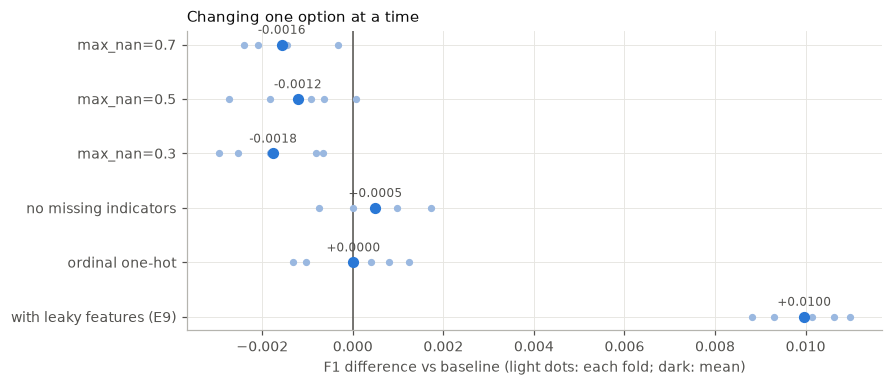

In [16]:
if results:
    # All configurations use the same folds, so compare them fold by fold (paired):
    # the fold-to-fold noise largely cancels in the differences.
    base = results["baseline"]["per_fold"]
    names = [n for n in results if n != "baseline"]
    delta = {n: results[n]["per_fold"] - base for n in names}
    print(f"baseline F1 {base.mean():.4f} ± {base.std():.4f} (mean ± std over 5 folds)\n")
    print(f"{'configuration':<26} {'F1':>7} {'Δ vs baseline':>14} {'folds better':>13}")
    for n in names:
        d = delta[n]
        print(f"{n:<26} {results[n]['f1']:>7.4f} {d.mean():>+8.4f} ± {d.std():.4f} {np.sum(d > 0):>8} / 5")

    fig, ax = plt.subplots(figsize=(8, 3.4), constrained_layout=True)
    yy = np.arange(len(names))
    ax.axvline(0, color=MUTED, lw=1)
    for y_, n in zip(yy, names):
        ax.scatter(delta[n], np.full(5, y_), s=14, color="#9ab8e0", zorder=2)
        ax.scatter(delta[n].mean(), y_, s=40, color=BLUE, zorder=3)
        ax.annotate(f"{delta[n].mean():+.4f}", (delta[n].mean(), y_), xytext=(0, 7),
                    textcoords="offset points", ha="center", fontsize=8, color=MUTED)
    ax.set_yticks(yy, names)
    ax.invert_yaxis()
    ax.set_xlabel("F1 difference vs baseline (light dots: each fold; dark: mean)")
    ax.set_title("Changing one option at a time")
    plt.show()

## Feature Leakage

In [17]:
present_tr, present_te = ~np.isnan(col("HAREHAB1")), ~np.isnan(col("HAREHAB1", x_test))
print(f"HAREHAB1 present: {present_tr.sum()} train rows (positive rate {y01[present_tr].mean():.0%}), "
      f"{present_te.sum()} test rows")
if results:
    for name in ["baseline", "with leaky features (E9)"]:
        r = results[name]
        pred = (r["oof"] >= r["threshold"]) * 1
        print(f"{name:<26} recall on HAREHAB1 rows {pred[present_tr].mean():.0%}, "
              f"F1 on all other rows {f1_score(y01[~present_tr], pred[~present_tr]):.4f}")

HAREHAB1 present: 773 train rows (positive rate 100%), 238 test rows
baseline                   recall on HAREHAB1 rows 57%, F1 on all other rows 0.4220
with leaky features (E9)   recall on HAREHAB1 rows 100%, F1 on all other rows 0.4248


**Takeaway.**
- `HAREHAB1` ("did you go to cardiac rehab after your heart attack?") is present for 773 training rows, **100 % positive**, and for **238 test rows**.
- Without it, the model already catches 57 % of those people from their other answers. With it, it catches all of them. That explains most of the +0.010; F1 on all the other rows moves only from 0.422 to 0.425 (the aspirin follow-ups).